In [1]:
from pathlib import Path
PROJECT_ROOT = Path.cwd().parent

import pandas as pd

pd.set_option('display.max_columns', None)  # none은 제한값 자리(몇개 열까지 보여줄까)
pd.set_option('display.max_rows', None)

# ============================================================
# 0. 데이터 불러오기: 2-5 train_test_comparison에서 제거된 이상치까지 반영된 데이터셋
# ============================================================

train = pd.read_parquet(PROJECT_ROOT / 'parqueted_data' / '3_train_clean3.parquet')
val = pd.read_parquet(PROJECT_ROOT / 'parqueted_data' / '3_val_clean3.parquet')

train_kf_oof = pd.read_parquet(PROJECT_ROOT / 'parqueted_data' / '0_kf_oof_train2_index_fixed.parquet')

print(train.shape, val.shape, train_kf_oof.shape)

from sklearn import set_config
set_config(display='text')
# scikit-learn의 HTML 출력 과정에서 발생한 cp949 간 UTF-8 충돌 때문에 넣는 코드

(616293, 35) (133316, 35) (616293, 40)


In [2]:
# ============================================================
# 0. 라이브러리 불러오기
# ============================================================

import numpy as np
import optuna

from catboost import CatBoostRegressor, CatBoostClassifier
from lightgbm import LGBMRegressor, LGBMClassifier

from sklearn.metrics import mean_squared_error, f1_score, confusion_matrix

c:\Users\20162180\AppData\Local\Programs\Python\Python314\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
# ============================================================
# 1. 컬럼군 정의
# ============================================================

target_col = 'target_maxrise_6h'  # 모델링 학습부터는 반드시 빼내야 함

# 수위 컬럼군
wl_cols = [
    'wl_t',
    'wl_t_minus_1h',
    'wl_t_minus_3h',
    'wl_t_minus_6h',
    'wl_t_minus_12h',
    'wl_t_minus_24h',
]

# 수위차분(wl_diff) 컬럼군
wl_diff_cols = [
    'wl_t',
    'wl_diff_1h',
    'wl_diff_3h',
    'wl_diff_6h',
    'wl_diff_12h',
    'wl_diff_24h'
]


# 강수 컬럼군
rain_cols = [
    # IMERG강우
    'imerg_rain_1h',
    'imerg_rain_6h',
    'imerg_rain_24h',
    # 지상강우
    'sfc_rain_1h',
    'sfc_rain_6h',
    'sfc_rain_24h',
    # 레이더 반사도
    'radar_reflectivity_mean',
    'radar_reflectivity_p95',
    'radar_reflectivity_ge20_fraction'
]

# 강우강도 컬럼군
rain_int_cols = [
    'imerg_rain_1h',
    'imerg_int_1to6h',
    'imerg_int_6to24h',
    'sfc_rain_1h',
    'sfc_int_1to6h',
    'sfc_int_6to24h'
]

# 환경 컬럼군
env_cols = [
    'cat_area',       # km²
    'wsarea',         # km²
    'mean_elevation', # m
    'mean_slope',     # °
    'urban_ratio',    # %
    'forest_ratio',   # %
    'stream_order'
]

num_cols = wl_cols + rain_cols + env_cols
num_cols_fe_wl = num_cols + [
    col for col in wl_diff_cols if col != 'wl_t'
]
num_cols_fe = num_cols_fe_wl + [
    col for col in rain_int_cols if col not in ['imerg_rain_1h', 'sfc_rain_1h']
]

print(f"""<변수개수 검증>
    수위변수: {len(wl_cols)}
    강우변수: {len(rain_cols)},
    환경변수: {len(env_cols)},
    수위차분(wl_t포함): {len(wl_diff_cols)},
    강우강도(rain_1h포함): {len(rain_int_cols)}
    기존 숫자열(수위 + 강우 + 환경): {len(num_cols)},
    수위차분추가 숫자열(수위 + 강우 + 환경 + 수위차분(wl_t제외)): {len(num_cols_fe_wl)},
    강우강도추가 숫자열(수위차분추가 숫자열 + 강우강도(rain_1h 2개제외)): {len(num_cols_fe)}
""")

<변수개수 검증>
    수위변수: 6
    강우변수: 9,
    환경변수: 7,
    수위차분(wl_t포함): 6,
    강우강도(rain_1h포함): 6
    기존 숫자열(수위 + 강우 + 환경): 22,
    수위차분추가 숫자열(수위 + 강우 + 환경 + 수위차분(wl_t제외)): 27,
    강우강도추가 숫자열(수위차분추가 숫자열 + 강우강도(rain_1h 2개제외)): 31



In [4]:
# ============================================================
# 2. 종속변수 설정
# ============================================================

y_train = train[target_col]
y_val = val[target_col]

In [6]:
# ============================================================
# 3. 고정 Fold 매핑 파일 불러오기
# ============================================================

kf_fold_fixed = pd.read_csv(
    PROJECT_ROOT / 'config' / '0_kf_event_fold_match.csv'
)

display(kf_fold_fixed.head())
print(kf_fold_fixed.shape)

,event_id,fold_num
0,1,5
1,2,1
2,3,3
3,4,3
4,5,1


(98, 2)


In [7]:
# ============================================================
# 4. Train 데이터에 기존 Fold 번호 매칭
# ============================================================

train['fold'] = train['event_id'].map(
    kf_fold_fixed.set_index('event_id')['fold_num']
)# ============================================================
# 4. Train 데이터에 기존 Fold 번호 매칭
# ============================================================

train['fold'] = train['event_id'].map(
    kf_fold_fixed.set_index('event_id')['fold_num']
)

# 매칭 결과 검증
print(train['fold'].value_counts().sort_index())
print('Fold 결측:', train['fold'].isna().sum())
print('강우사상 수:', train.groupby('fold')['event_id'].nunique())

fold
1    122996
2    123399
3    123399
4    123216
5    123283
Name: count, dtype: int64
Fold 결측: 0
강우사상 수: fold
1    16
2    21
3    21
4    20
5    20
Name: event_id, dtype: int64


In [8]:
# ============================================================
# 5. 모델 학습용 독립변수 설정
# ============================================================

X_train = train[num_cols_fe + ['station_id']].copy()
X_val = val[num_cols_fe + ['station_id']].copy()

cat_cols = ['station_id']

# LightGBM 범주형 변수 지정
X_train[cat_cols] = X_train[cat_cols].astype('category')
X_val[cat_cols] = X_val[cat_cols].astype('category')

print(X_train.shape, X_val.shape)
print(X_train[cat_cols].dtypes)

(616293, 32) (133316, 32)
station_id    category
dtype: object


In [9]:
# ============================================================
# 5-1. 모델 학습 전 데이터 검증
# ============================================================

# Train, X_train, y_train 인덱스 일치
assert train.index.equals(X_train.index)
assert train.index.equals(y_train.index)

# Validation 인덱스 일치
assert val.index.equals(X_val.index)
assert val.index.equals(y_val.index)

# Fold 매칭 및 데이터 검증
assert train['fold'].notna().all()
assert set(train['fold'].unique()) == {1, 2, 3, 4, 5}
assert train.groupby('event_id')['fold'].nunique().eq(1).all()

# 종속변수 결측 검증
assert y_train.notna().all()

# 범주형 변수 검증
assert str(X_train['station_id'].dtype) == 'category'
assert str(X_val['station_id'].dtype) == 'category'

print('학습 전 검증 완료')

학습 전 검증 완료


In [10]:
# K-Fold 1개 fold씩 제외하고 CATBoost 4-fold 교차검증으로 제외한 fold의 잔차구하기
# 제외한 fold들의 잔차를 합쳐서 임계치 기준으로 'down', 'normal', 'over' 분류 정답라벨을 매기기 -> 총 5개 분류모델
# 최종결과물: train + 'resid_dir(분류결과)'컬럼
# ============================================================
# 6. 내부 4-Fold 잔차 생성 및 분류모델 학습
# ============================================================

# 분류 임계치 설정
thresholds = [0.5, 0.75, 1.0, 1.2]

assert all(t is not None and t > 0 for t in thresholds)
assert len(set(thresholds)) == len(thresholds)

# 임계치별 Train 분류 예측값 저장
resid_dir_preds = {
    threshold: np.full(len(train), '', dtype=object)
    for threshold in thresholds
}

# 임계치별 Fold 분류모델 저장 (Validation 예측용)
resid_dir_models = {
    threshold: []
    for threshold in thresholds
}

# ------------------------------------------------------------
# 6-1. 바깥쪽 5-Fold 반복
# ------------------------------------------------------------

for fold in range(1, 6):

    # 분류 예측 대상 Fold 제외
    outer_tr_idx = np.flatnonzero(train['fold'].to_numpy() != fold)
    outer_va_idx = np.flatnonzero(train['fold'].to_numpy() == fold)

    # 내부 4-Fold OOF 잔차 저장
    inner_resid = np.full(len(outer_tr_idx), np.nan)

    # --------------------------------------------------------
    # 6-2. 내부 4-Fold 회귀학습 및 OOF 잔차 생성
    # --------------------------------------------------------

    for inner_fold in range(1, 6):

        if inner_fold == fold:
            continue

        # 내부 Train, Validation 분할
        inner_tr_idx = np.flatnonzero(
            train['fold'].iloc[outer_tr_idx].to_numpy() != inner_fold
        )
        inner_va_idx = np.flatnonzero(
            train['fold'].iloc[outer_tr_idx].to_numpy() == inner_fold
        )

        X_inner_tr = X_train.iloc[outer_tr_idx].iloc[inner_tr_idx]
        X_inner_va = X_train.iloc[outer_tr_idx].iloc[inner_va_idx]

        y_inner_tr = y_train.iloc[outer_tr_idx].iloc[inner_tr_idx]
        y_inner_va = y_train.iloc[outer_tr_idx].iloc[inner_va_idx]

        # LightGBM 회귀모델
        model_lgb_reg = LGBMRegressor(
            random_state=42,
            verbosity=-1
        )

        model_lgb_reg.fit(
            X_inner_tr,
            y_inner_tr,
            categorical_feature=cat_cols
        )

        # 내부 OOF 잔차: 실제값 - 예측값
        inner_resid[inner_va_idx] = (
            y_inner_va.to_numpy() - model_lgb_reg.predict(X_inner_va)
        )

    assert not np.isnan(inner_resid).any()

    # --------------------------------------------------------
    # 6-3. 임계치별 분류 라벨 생성 및 분류학습
    # --------------------------------------------------------

    for threshold in thresholds:

        # 잔차 기준 이진분류 라벨 생성
        resid_dir_labels = np.where(
            inner_resid > threshold,
            'down',
            'normal'
        )

        # LightGBM 분류모델
        model_lgb_clf = LGBMClassifier(
            random_state=42,
            verbosity=-1
        )

        model_lgb_clf.fit(
            X_train.iloc[outer_tr_idx],
            resid_dir_labels,
            categorical_feature=cat_cols
        )

        # 제외한 Fold 분류 예측
        resid_dir_preds[threshold][outer_va_idx] = model_lgb_clf.predict(
            X_train.iloc[outer_va_idx]
        )

        # Validation 예측용 분류모델 저장
        resid_dir_models[threshold].append(model_lgb_clf)

        print(
            f'Fold {fold} | '
            f'threshold={threshold} | '
            f'분류 완료'
        )

# ------------------------------------------------------------
# 6-4. 임계치별 Train 분류결과 결합
# ------------------------------------------------------------

for threshold in thresholds:

    assert (resid_dir_preds[threshold] != '').all()
    assert len(resid_dir_models[threshold]) == 5

    train[f'resid_dir_{threshold}'] = resid_dir_preds[threshold]

    print(f'\n임계치: {threshold}')
    print(train[f'resid_dir_{threshold}'].value_counts())

Fold 1 | threshold=0.5 | 분류 완료
Fold 1 | threshold=0.75 | 분류 완료
Fold 1 | threshold=1.0 | 분류 완료
Fold 1 | threshold=1.2 | 분류 완료
Fold 2 | threshold=0.5 | 분류 완료
Fold 2 | threshold=0.75 | 분류 완료
Fold 2 | threshold=1.0 | 분류 완료
Fold 2 | threshold=1.2 | 분류 완료
Fold 3 | threshold=0.5 | 분류 완료
Fold 3 | threshold=0.75 | 분류 완료
Fold 3 | threshold=1.0 | 분류 완료
Fold 3 | threshold=1.2 | 분류 완료
Fold 4 | threshold=0.5 | 분류 완료
Fold 4 | threshold=0.75 | 분류 완료
Fold 4 | threshold=1.0 | 분류 완료
Fold 4 | threshold=1.2 | 분류 완료
Fold 5 | threshold=0.5 | 분류 완료
Fold 5 | threshold=0.75 | 분류 완료
Fold 5 | threshold=1.0 | 분류 완료
Fold 5 | threshold=1.2 | 분류 완료

임계치: 0.5
resid_dir_0.5
normal    614678
down        1615
Name: count, dtype: int64

임계치: 0.75
resid_dir_0.75
normal    615077
down        1216
Name: count, dtype: int64

임계치: 1.0
resid_dir_1.0
normal    615113
down        1180
Name: count, dtype: int64

임계치: 1.2
resid_dir_1.2
normal    614942
down        1351
Name: count, dtype: int64


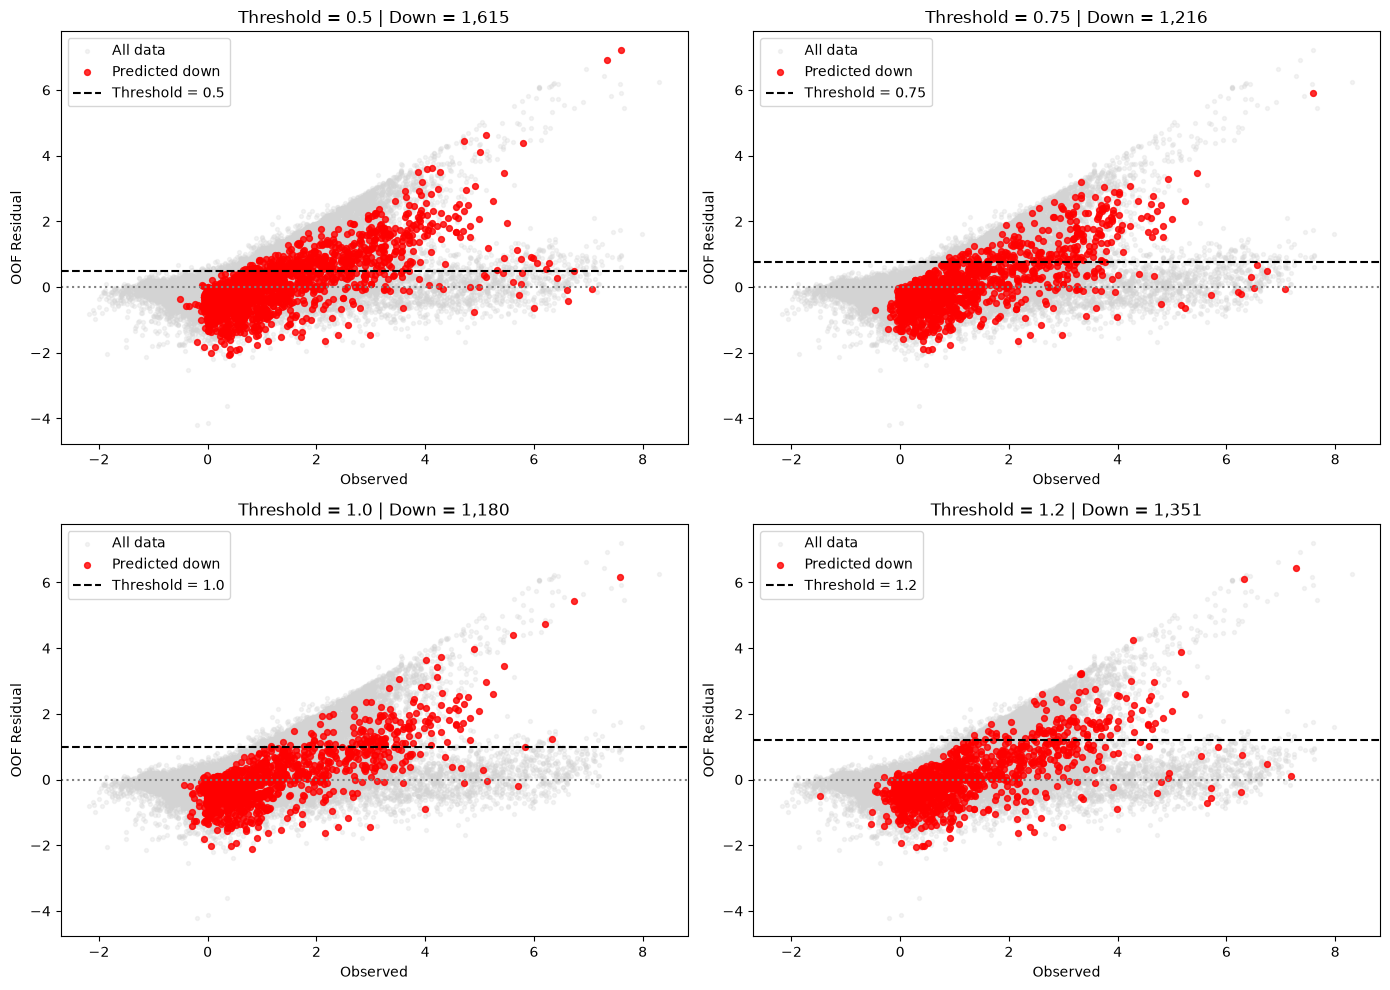

In [12]:
# ============================================================
# 6-5. Train OOF 잔차 기반 이진분류 결과 시각화
# ============================================================

import matplotlib.pyplot as plt

# 기존 OOF 잔차를 Train 인덱스에 맞춰 정렬
assert train.index.is_unique
assert train_kf_oof.index.is_unique
assert train.index.isin(train_kf_oof.index).all()

oof_resid = train_kf_oof['resid'].reindex(train.index)

assert oof_resid.notna().all()

# 임계치별 산점도
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for i, threshold in enumerate(thresholds):

    # 그래프 위치 지정
    ax = axes[i // 2][i % 2]

    # 분류모델이 down으로 예측한 데이터
    mask_down = train[f'resid_dir_{threshold}'] == 'down'

    # 전체 OOF 잔차
    ax.scatter(
        y_train,
        oof_resid,
        s=8,
        alpha=0.25,
        color='lightgray',
        label='All data',
        zorder=1
    )

    # down으로 예측한 데이터만 강조
    ax.scatter(
        y_train[mask_down],
        oof_resid[mask_down],
        s=18,
        alpha=0.8,
        color='red',
        label='Predicted down',
        zorder=2
    )

    # 잔차 임계치 기준선
    ax.axhline(
        threshold,
        color='black',
        linestyle='--',
        label=f'Threshold = {threshold}'
    )

    ax.axhline(0, color='gray', linestyle=':')

    ax.set_title(
        f'Threshold = {threshold} | '
        f'Down = {mask_down.sum():,}'
    )
    ax.set_xlabel('Observed')
    ax.set_ylabel('OOF Residual')
    ax.legend()

plt.tight_layout()
plt.show()

In [ ]:
# 마지막 Fold의 실제 잔차 라벨 분포 확인
for threshold in thresholds:
    resid_dir_labels = np.select(
        [inner_resid < -threshold, inner_resid > threshold],
        ['down', 'over'],
        default='normal'
    )

    print(f'\n임계치: {threshold}')
    print(pd.Series(resid_dir_labels).value_counts())
    print(pd.Series(resid_dir_labels).value_counts(normalize=True).round(4))


임계치: 0.75
normal    483457
over        7560
down        1993
Name: count, dtype: int64
normal    0.9806
over      0.0153
down      0.0040
Name: proportion, dtype: float64

임계치: 1.2
normal    489113
over        3463
down         434
Name: count, dtype: int64
normal    0.9921
over      0.0070
down      0.0009
Name: proportion, dtype: float64


In [ ]:
# ============================================================
# 7. Validation 분류 예측 (5-Fold 다수결)
# ============================================================

for threshold in thresholds:

    # Fold별 분류모델 5개의 Validation 예측
    val_preds = pd.DataFrame({
        f'fold_{i}': model.predict(X_val)
        for i, model in enumerate(resid_dir_models[threshold], start=1)
    }, index=val.index)

    # 다수결로 최종 분류 결정
    # 동률 발생 시 normal 우선
    val[f'resid_dir_{threshold}'] = val_preds.apply(
        lambda row: row.value_counts().reindex(
            ['normal', 'down', 'over'], fill_value=0
        ).idxmax(),
        axis=1
    )

    print(f'\n임계치: {threshold}')
    print(val[f'resid_dir_{threshold}'].value_counts())
    print('결측:', val[f'resid_dir_{threshold}'].isna().sum())


임계치: 0.75
resid_dir_0.75
normal    133157
over         120
down          39
Name: count, dtype: int64
결측: 0

임계치: 1.2
resid_dir_1.2
normal    133263
over          47
down           6
Name: count, dtype: int64
결측: 0


In [ ]:
# val에도 + 'expect_direction(분류결과)'컬럼: 정답 라벨링
# 방법은 위 5개 분류모델의 보팅(다수결)

# CatBoost 기준모델, 'expect_direction(분류결과)' 포함 train셋으로 학습, val셋으로 종속변수(최대수위상승량) 전후 RMSE 비교

In [ ]:
# ============================================================
# 9. 잔차 분류변수 추가 CatBoost 학습 및 RMSE 비교
# ============================================================

results = {}
preds = {}

for threshold in thresholds:

    # --------------------------------------------------------
    # 9-1. 임계치별 독립변수 구성
    # --------------------------------------------------------

    X_train_cb = train[num_cols_fe + ['station_id', f'resid_dir_{threshold}']].copy()
    X_val_cb = val[num_cols_fe + ['station_id', f'resid_dir_{threshold}']].copy()

    cat_cols_cb = ['station_id', f'resid_dir_{threshold}']

    # CatBoost 범주형 변수 처리
    X_train_cb[cat_cols_cb] = X_train_cb[cat_cols_cb].astype(str)
    X_val_cb[cat_cols_cb] = X_val_cb[cat_cols_cb].astype(str)

    # --------------------------------------------------------
    # 9-2. CatBoost 회귀모델 학습
    # --------------------------------------------------------

    model_cb = CatBoostRegressor(
        iterations=3000,
        loss_function='RMSE',
        random_seed=42,
        verbose=200
    )

    model_cb.fit(
        X_train_cb,
        y_train,
        cat_features=cat_cols_cb,
        eval_set=(X_val_cb, y_val),
        early_stopping_rounds=100
    )

    # --------------------------------------------------------
    # 9-3. Train / Validation 예측 및 RMSE
    # --------------------------------------------------------

    train_pred = model_cb.predict(X_train_cb)
    val_pred = model_cb.predict(X_val_cb)

    train_rmse = np.sqrt(mean_squared_error(y_train, train_pred))
    val_rmse = np.sqrt(mean_squared_error(y_val, val_pred))

    results[threshold] = {
        'train_rmse': train_rmse,
        'val_rmse': val_rmse,
        'gap': val_rmse - train_rmse,
        'best_iteration': model_cb.best_iteration_
    }

    preds[threshold] = val_pred

    print(
        f'임계치 {threshold} | '
        f'Train RMSE: {train_rmse:.6f} | '
        f'Val RMSE: {val_rmse:.6f} | '
        f'Best iteration: {model_cb.best_iteration_}'
    )

# ------------------------------------------------------------
# 9-4. 임계치별 결과 비교
# ------------------------------------------------------------

result_df = pd.DataFrame.from_dict(
    results,
    orient='index'
)

display(result_df)

Learning rate set to 0.071425
0:	learn: 0.3895064	test: 0.3444704	best: 0.3444704 (0)	total: 112ms	remaining: 5m 35s
200:	learn: 0.2301350	test: 0.2026304	best: 0.2026304 (200)	total: 19.7s	remaining: 4m 34s
400:	learn: 0.2180558	test: 0.1973956	best: 0.1973877 (399)	total: 39.1s	remaining: 4m 13s
600:	learn: 0.2111609	test: 0.1950527	best: 0.1950527 (600)	total: 58.2s	remaining: 3m 52s
800:	learn: 0.2061911	test: 0.1938839	best: 0.1938446 (796)	total: 1m 17s	remaining: 3m 32s
1000:	learn: 0.2018463	test: 0.1934123	best: 0.1933648 (980)	total: 1m 36s	remaining: 3m 13s
1200:	learn: 0.1981868	test: 0.1931265	best: 0.1931163 (1196)	total: 1m 55s	remaining: 2m 53s
1400:	learn: 0.1949066	test: 0.1927323	best: 0.1927314 (1399)	total: 2m 15s	remaining: 2m 34s
1600:	learn: 0.1919671	test: 0.1925886	best: 0.1925231 (1574)	total: 2m 34s	remaining: 2m 15s
Stopped by overfitting detector  (100 iterations wait)

bestTest = 0.1925009423
bestIteration = 1655

Shrink model to first 1656 iterations.
임계

,train_rmse,val_rmse,gap,best_iteration
0.75,0.190503,0.192501,0.001998,1655
1.20,0.193033,0.193093,0.000061,1479


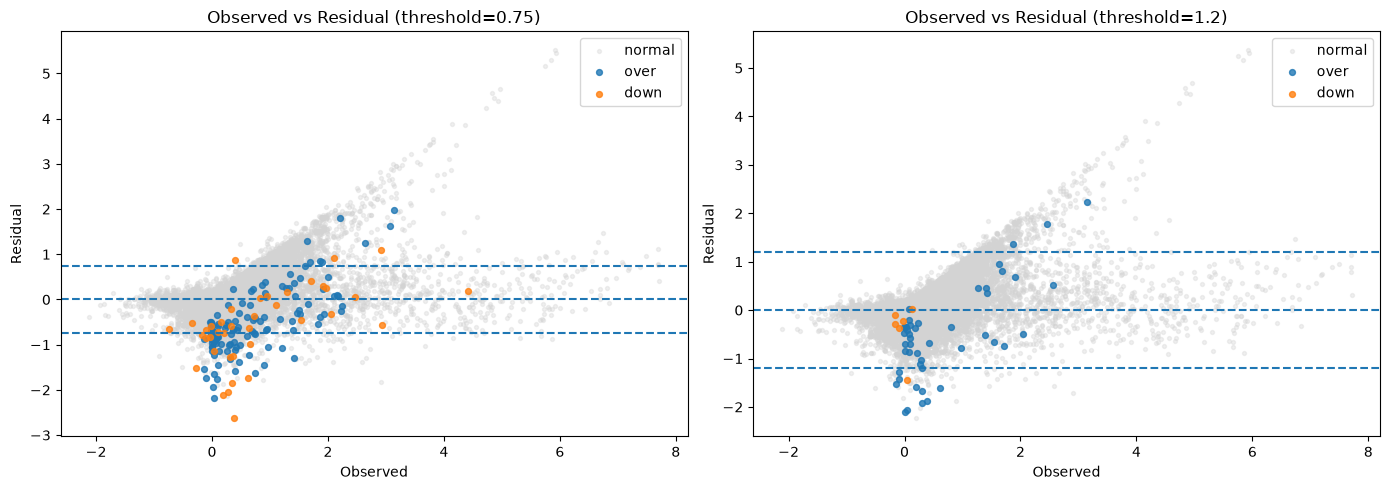

In [ ]:
# ============================================================
# 14. Validation - Observed vs Residual 플롯
# ============================================================

import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, threshold in zip(axes, thresholds):

    val_pred = preds[threshold]
    residual = y_val.to_numpy() - val_pred
    resid_dir = val[f'resid_dir_{threshold}']

    # normal
    mask_normal = resid_dir == 'normal'
    ax.scatter(
        y_val[mask_normal],
        residual[mask_normal],
        s=8,
        alpha=0.35,
        color='lightgray',
        label='normal',
        zorder=1
    )

    # over
    mask_over = resid_dir == 'over'
    ax.scatter(
        y_val[mask_over],
        residual[mask_over],
        s=18,
        alpha=0.8,
        label='over'
    )

    # down
    mask_down = resid_dir == 'down'
    ax.scatter(
        y_val[mask_down],
        residual[mask_down],
        s=18,
        alpha=0.8,
        label='down'
    )

    ax.axhline(0, linestyle='--')
    ax.axhline(threshold, linestyle='--')
    ax.axhline(-threshold, linestyle='--')

    ax.set_title(f'Observed vs Residual (threshold={threshold})')
    ax.set_xlabel('Observed')
    ax.set_ylabel('Residual')
    ax.legend()

plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# 10. 신규 변수 중요도 및 SSE 분석 (임계치 1.0)
# ============================================================

# ------------------------------------------------------------
# 10-1. CatBoost 변수 중요도
# ------------------------------------------------------------

feature_importance = pd.Series(
    model_cb.feature_importances_,
    index=X_train_cb.columns
).sort_values(ascending=False)

display(feature_importance.to_frame('importance'))

print(
    'resid_dir_1 중요도:',
    feature_importance['resid_dir_1']
)

# ------------------------------------------------------------
# 10-2. Validation 분류별 RMSE 및 SSE 기여율
# ------------------------------------------------------------

val_resid_analysis = pd.DataFrame({
    'resid_dir': val['resid_dir_1'],
    'residual_sq': (y_val - val_pred) ** 2
})

resid_dir_result = (
    val_resid_analysis
    .groupby('resid_dir')
    .agg(
        count=('residual_sq', 'size'),
        sse=('residual_sq', 'sum'),
        mse=('residual_sq', 'mean')
    )
)

resid_dir_result['rmse'] = np.sqrt(resid_dir_result['mse'])

resid_dir_result['sse_pct'] = (
    resid_dir_result['sse'] /
    resid_dir_result['sse'].sum() * 100
)

display(resid_dir_result)

,importance
wl_diff_6h,23.726101
wl_diff_1h,15.404224
wl_t_minus_1h,4.363681
sfc_rain_24h,4.114593
radar_reflectivity_p95,4.018973
wsarea,3.848484
imerg_rain_1h,3.825138
station_id,3.389662
wl_diff_24h,3.303121
sfc_rain_1h,2.807237


resid_dir_1 중요도: 1.1319087592690282


,count,sse,mse,rmse,sse_pct
resid_dir,,,,,
down,9,3.740013,0.415557,0.644637,0.075501
normal,133239,4898.229800,0.036763,0.191736,98.882807
over,68,51.600919,0.758837,0.871113,1.041691


In [ ]:
# ============================================================
# 12. 임계치별 실험결과 누적 저장
# ============================================================

# 1. RMSE 비교 결과 누적
result_path = PROJECT_ROOT / 'result' / 'resid_dir_rmse_01.csv'

result_saved = pd.read_csv(result_path, index_col=0)
result_saved = pd.concat([result_saved, result_df])
result_saved = result_saved[~result_saved.index.duplicated(keep='last')]
result_saved.to_csv(result_path)

# 2. Train 분류결과 누적
train_path = PROJECT_ROOT / 'result' / 'resid_dir_train_01.parquet'

train_saved = pd.read_parquet(train_path)

for threshold in thresholds:
    train_saved[f'resid_dir_{threshold}'] = train[f'resid_dir_{threshold}']

train_saved.to_parquet(train_path)

# 3. Validation 분류결과 및 예측값 누적
val_path = PROJECT_ROOT / 'result' / 'resid_dir_val_01.parquet'

val_saved = pd.read_parquet(val_path)

for threshold in thresholds:
    val_saved[f'resid_dir_{threshold}'] = val[f'resid_dir_{threshold}']
    val_saved[f'pred_{threshold}'] = preds[threshold]

val_saved.to_parquet(val_path)

print('실험결과 누적 저장 완료')

실험결과 누적 저장 완료
